# M1a

In [ ]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys

# Set a random seed for reproducibility
nprandom.seed(42)

# -----------------------------------------------------------------------------
# LOGGING SETUP
# -----------------------------------------------------------------------------

def setup_logging():
    """Setup comprehensive logging for the simulation"""
    # Create formatters
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )

    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create main logger
    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    # Console handler for main progress
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    # File handler for detailed logs
    file_handler = logging.FileHandler('logs/M1a_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    # Progress logger (separate to avoid cluttering main log)
    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    # Progress file handler
    progress_handler = logging.FileHandler('logs/M1a_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""

    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        self.delta_progress[delta_idx] += 1

        # Calculate progress metrics
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            # Log progress
            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

            # Log delta-specific progress every completed task (since there are so few)
            if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
                delta_status = []
                for i, delta in enumerate(self.delta_list):
                    progress = self.delta_progress[i]
                    delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")

                self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker
progress_tracker = True

# -----------------------------------------------------------------------------
# 1. Helper Function for a Single Parallel Job
# -----------------------------------------------------------------------------

def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates):
    """
    Executes a single simulation trial for a given delta.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker

    # Unpack parameters for this specific job
    i, δ, j = params

    trial_start_time = time.time()

    # Log trial start (log all trials since there are so few)
    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Sparse Signal Prior Setup
    κ = 1.0
    α = 0.3 # fraction of nonzeros
    σ_l_arr = κ * np.sqrt(δ) * np.array([1, 1]) # signal standard deviation, multiply by sqrt(δ) to keep SNR constant as δ varies
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = nprandom.normal(0, 1, size=(n,)) * noise_std
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise

    # Generate a non-trivial p times p covariance matrix, like involving some s^r structure
    r = 0.2  # Correlation coefficient for off-diagonal elements
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))
    # Right multiply X by the square root of Sigma to introduce correlation
    X = X @ np.linalg.cholesky(Sigma).T

    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    # Important: for competing methods, we ususally require something like X_ij ~ N(0, 1) (not 1/n),
    # so we rescale X and B̃ accordingly to keep Θ the same.
    X_scaled = X * np.sqrt(n) # Use this for methods expecting N(0,1) features
    B̃_scaled = B̃ / np.sqrt(n)

    Θ = X_scaled @ B̃_scaled # Keep Θ consistent based on scaled X and B̃
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)

    # Standardize y
    y_standardized = np.asarray(y / (α*κ**2 + noise_std**2))
    print(f"y std: {np.std(y_standardized):.4f}, mean: {np.mean(y_standardized):.4f}")

    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators ---
    trial_results = {}
    methods_status = {} # To track success/failure of each method in this trial

    # Method 1: McScan Weighted ERM
    method_name = 'McScan'
    try:
        method_start = time.time()
        print(f"Running {method_name} on params: ", params)
        cp_mcscan = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized, num_chgpts = len(fractional_chgpt_locations)))
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_mcscan, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_mcscan[cp_mcscan != -1])
        trial_results[f'chgpts_{method_name}'] = cp_mcscan.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([]) # Store empty array for failed changepoints
        methods_status[method_name] = False

    # Method 2: DCDP (Dynamic Changepoint Detection via Penalized Likelihood)
    method_name = 'DCDP'
    try:
        print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        # cp_dcdp = np.asarray(WERM.comparison.DCDP(np.array(X_scaled), y_standardized, λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # cp_dcdp = np.array([-1]) # Placeholder, because DCDP outputs >10 change points, which is not relevant for this experiment. 
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        assert len(true_chgpts) == 1
        print(f"True changepoints: {true_chgpts}, DCDP changepoints: {cp_dcdp}")
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.closest_point_distance(cp_dcdp, true_chgpts) # For DCDP, select the closest point
        trial_results[f'size_{method_name}'] = len(cp_dcdp[cp_dcdp != -1])
        trial_results[f'chgpts_{method_name}'] = cp_dcdp.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Method 3: MOSEG (Moving Segmentations)
    method_name = 'MOSEG'
    try:
        print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        res = WERM.comparison.MOSEG(np.array(X_scaled), y_standardized, num_chgpts=len(fractional_chgpt_locations))
        cp_moseg = res[2]  # Returns the refined estimate
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_moseg, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_moseg[cp_moseg != -1])
        trial_results[f'chgpts_{method_name}'] = cp_moseg.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Method 4: WERM (Weighted ERM)
    method_name = 'WERM'
    try:
        print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        # Delta = lambda n: int(n/40)
        Delta = lambda n: 1
        gamma_hat_1 = 0.0
        cp_werm = WERM.estimators.weighted_erm(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_1, 
            L_is_upper_bound = False, return_B_hat=False, 
            brute_force=False, P_func=P_func)
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_werm, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_werm[cp_werm != -1])
        trial_results[f'chgpts_{method_name}'] = cp_werm.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status # Store status for this trial

    trial_total_time = time.time() - trial_start_time

    # Log detailed trial completion for all trials (since there are so few)
    progress_logger.info(
        f"Completed trial {j+1} for δ={δ:.1f}: "
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s, "
        f"McScan={'OK' if methods_status['McScan'] else 'FAIL'} ({trial_results['runtime_McScan']:.1f}s), "
        f"DCDP={'OK' if methods_status['DCDP'] else 'FAIL'} ({trial_results['runtime_DCDP']:.1f}s), "
        f"MOSEG={'OK' if methods_status['MOSEG'] else 'FAIL'} ({trial_results['runtime_MOSEG']:.1f}s), "
        f"WERM={'OK' if methods_status['WERM'] else 'FAIL'} ({trial_results['runtime_WERM']:.1f}s))"
    )

    # Update global progress tracker
    if progress_tracker:
        progress_tracker.update(i)

    # Return the indices and the dictionary of results for this trial
    return i, j, trial_results

# -----------------------------------------------------------------------------
# 2. Main Script Setup
# -----------------------------------------------------------------------------

main_logger.info("Starting McScan, DCDP, MOSEG, WERM simulation M1a with enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 2
noise_std = np.sqrt(0.5)
# noise_std = 0.1
δ_list = np.arange(1.0, 6.0, 1.0)  # List of δ values
num_trials = 30
fractional_chgpt_locations = np.array([0.4])
n_jobs = -1 # Use all available CPU cores
# n_jobs = 1

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f"  p (features): {p}")
main_logger.info(f"  L (signals): {L}")
main_logger.info(f"  noise_std: {noise_std}")
main_logger.info(f"  δ_list: {δ_list}")
main_logger.info(f"  num_trials: {num_trials}")
main_logger.info(f"  fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f"  n_jobs: {n_jobs}")
main_logger.info(f"  Total tasks: {len(δ_list) * num_trials}")

# Methods to be evaluated
methods_to_evaluate = ['McScan', 'DCDP', 'MOSEG', 'WERM']

# Results Storage
results = {
    # Store successful trial counts per method and delta
    'successful_trials': {method: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

# Dynamically add result arrays for each method and metric
for method in methods_to_evaluate:
    results[f'haus_{method}'] = np.full((len(δ_list), num_trials), np.nan) # Initialize with NaN
    results[f'size_{method}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method}'] = [] # Storing all changepoints for histograms

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)

# L1 Penalty function
reg_constant = 1e-3
def P_func(beta):
    """L1 penalty function for regularization"""
    return reg_constant * jnp.sum(jnp.abs(beta))

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-1, 2, 5)

# -----------------------------------------------------------------------------
# 3. Parallel Execution
# -----------------------------------------------------------------------------

# Create a list of all tasks to be executed
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]

main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Expected computation time estimation
single_trial_estimate = 30.0 * len(methods_to_evaluate) # Rough estimate in seconds per trial (adjusted for all methods)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)

main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

# Initialize progress tracker
progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)

simulation_start_time = time.time()

# Run all trials in parallel
try:
    # Run parallel computation
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )

    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time

    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)

except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# -----------------------------------------------------------------------------
# 4. Aggregate Results
# -----------------------------------------------------------------------------

main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

# Populate the results dictionary from the list returned by the parallel execution
for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method in methods_to_evaluate:
        # Only store results if the method succeeded in this trial
        if trial_result['methods_status'][method]:
            results[f'haus_{method}'][i, j] = trial_result[f'haus_{method}']
            results[f'size_{method}'][i, j] = trial_result[f'size_{method}']
            results[f'runtime_{method}'][i, j] = trial_result[f'runtime_{method}']
            results['successful_trials'][method][i] += 1
        results[f'chgpts_{method}'].append((i, trial_result[f'chgpts_{method}']))


    # Store changepoint locations and metadata for histogram plotting
    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)

for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method in methods_to_evaluate:
        # Use nanmean and nanstd to ignore NaN values (failed trials)
        avg_haus = np.nanmean(results[f'haus_{method}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method}'][i, :])
        avg_size = np.nanmean(results[f'size_{method}'][i, :])
        std_size = np.nanstd(results[f'size_{method}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method}'][i, :])
        num_success = results['successful_trials'][method][i]

        main_logger.info(f"  {method} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f"  {method} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f"  {method} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f"  {method} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'font.size': 14,           # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,       # Enable LaTeX rendering
    'axes.linewidth': 1.5,     # Thicker axes
    'axes.labelsize': 16,      # Larger axis labels
    'axes.titlesize': 18,      # Larger titles
    'xtick.labelsize': 14,     # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,     # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 300,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT

print(f"Using palette: {PAL[:len(methods_to_evaluate)]} (Paul Tol Vibrant)")

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Calculate percentiles for asymmetric error bars
    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1) # Use nanmean
        p25 = np.nanpercentile(data, 25, axis=1) # Use nanpercentile
        p75 = np.nanpercentile(data, 75, axis=1) # Use nanpercentile

        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)

        # Fallback for cases with too few valid data points for percentiles
        # if np.any(np.isnan(p25)) or np.any(np.isnan(p75)):
        #     std_errs = np.nanstd(data, axis=1)
        #     return [std_errs, std_errs]

        return [lower_errors, upper_errors]

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    markers = ['o', 's', 'D', '^']
    linestyles = ['-', '--', '-.', ':']
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method in enumerate(methods):
        data = results[f'haus_{method}']
        # Filter out rows where all values are NaN before calculating means and errors for plotting
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices): # If all trials failed for this method/delta, skip plotting
            main_logger.warning(f"No successful trials for {method} (Hausdorff). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)

    # Cleaner x-axis with fewer ticks
    ax.set_xticks(δ_list[::2])  # Show every other tick
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method in enumerate(methods):
        data = results[f'size_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Size). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)

    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method in enumerate(methods):
        data = results[f'runtime_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Runtime). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)

    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]

        for method_idx, method in enumerate(methods):
            data = results[f'{metric}_{method}']
            valid_indices = ~np.all(np.isnan(data), axis=1)
            if not np.any(valid_indices):
                main_logger.warning(f"No successful trials for {method} ({metric}). Skipping plot for this metric.")
                continue

            means = np.nanmean(data, axis=1)

            # Calculate confidence intervals (10th and 90th percentiles), ignoring NaNs
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)

            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                           alpha=0.15, zorder=1)

            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                   marker='o', markersize=9, label=labels[method_idx], zorder=3,
                   markeredgewidth=2, markeredgecolor='white')

        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                      linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)

        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]

        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []

            # Adjust spacing between boxes for each delta
            spacing = len(methods) + 1 # Add extra space between groups
            for method_idx, method in enumerate(methods):
                data = results[f'{metric}_{method}'][delta_idx, :]
                # Filter out NaN values for box plot to only show successful trials
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0: # Only plot if there is valid data
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")


            # Create publication-ready box plots
            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                               patch_artist=True, showfliers=True,
                               flierprops=dict(marker='o', markersize=4, alpha=0.6),
                               medianprops=dict(color='white', linewidth=2.5),
                               boxprops=dict(linewidth=1.5),
                               whiskerprops=dict(linewidth=1.5),
                               capprops=dict(linewidth=1.5))

                # Color the boxes
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        # Set x-axis labels - only show every other delta for cleanliness
        delta_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Add legend
        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                       alpha=0.8, edgecolor='black',
                                       linewidth=1.5, label=labels[i])
                         for i in range(len(methods))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                 frameon=True, edgecolor='black', framealpha=0.95)

        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                      linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot):
    """
    Publication-ready changepoint location histograms
    """

    method_names = {
        'McScan': r'\textbf{McScan}',
        'DCDP': r'\textbf{DCDP}',
        'MOSEG': r'\textbf{MOSEG}',
        'WERM': r'\textbf{WERM}'
    }

    # Use consistent colors from main palette
    method_colors = {
        'McScan': PAL[0],
        'DCDP': PAL[1],
        'MOSEG': PAL[2],
        'WERM': PAL[3]
    }

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list

    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot),
                             figsize=(6*len(methods_to_plot), 4*len(selected_deltas)))

    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(methods_to_plot) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)

        for col, method in enumerate(methods_to_plot):
            ax = axes[row, col]
            ax.set_facecolor('white')

            # Collect changepoints for the current delta and method
            all_chgpts = []
            # Iterate through the raw stored changepoint results to filter by delta_idx
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method}']:
                if stored_delta_idx == delta_idx:
                    # Check if the trial was successful for this method
                    # (we implicitly know if it was successful if chgpts_data is not empty/NaN-like)
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1] # Filter out -1 sentinels
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                              color=method_colors[method],
                                              density=True, edgecolor='white',
                                              linewidth=1.5)

                # Add KDE overlay if we have enough points
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                           alpha=0.9, label=r'\textbf{KDE}')

            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                       transform=ax.transAxes, ha='center', va='center',
                       fontsize=14, alpha=0.7, style='italic')

            # True changepoints with thicker lines
            # Get true changepoints for the current delta_idx
            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n # Ensure true changepoints are also fractional
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")

            ax.set_xlim(0, 1)

            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names[method]}', fontsize=18, pad=15)

            # Add n value annotation
            if col == len(methods_to_plot)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                       rotation=90, verticalalignment='center', fontsize=14,
                       fontweight='bold')

            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()

print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot=['McScan', 'DCDP', 'MOSEG', 'WERM'])

plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Optional: Save figures in high quality
# plt.savefig('weighted_erm_analysis.pdf', dpi=300, bbox_inches='tight')
# plt.savefig('weighted_erm_analysis.png', dpi=300, bbox_inches='tight')

# Save results to a file for later analysis, with all relevant experiment parameters included also in the name
import pickle
with open(f"results/M1a_all_methods_results_p{p}_L{L}_noisestd{noise_std}_{'_'.join(map(str, map(str, δ_list.astype(int))))}_{num_trials}.pkl", 'wb') as f: # Adjust filename for int δ_list
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'] # Save successful trial counts
        }
    }, f)

In [ ]:
# %matplotlib inline
# import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'font.size': 14,           # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,       # Enable LaTeX rendering
    'axes.linewidth': 1.5,     # Thicker axes
    'axes.labelsize': 16,      # Larger axis labels
    'axes.titlesize': 18,      # Larger titles
    'xtick.labelsize': 14,     # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,     # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 300,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT

print(f"Using palette: {PAL[:len(methods_to_evaluate)]} (Paul Tol Vibrant)")

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Calculate percentiles for asymmetric error bars
    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1) # Use nanmean
        p25 = np.nanpercentile(data, 25, axis=1) # Use nanpercentile
        p75 = np.nanpercentile(data, 75, axis=1) # Use nanpercentile

        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)

        # Fallback for cases with too few valid data points for percentiles
        # if np.any(np.isnan(p25)) or np.any(np.isnan(p75)):
        #     std_errs = np.nanstd(data, axis=1)
        #     return [std_errs, std_errs]

        return [lower_errors, upper_errors]

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    markers = ['o', 's', 'D', '^']
    linestyles = ['-', '--', '-.', ':']
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method in enumerate(methods):
        data = results[f'haus_{method}']
        # Filter out rows where all values are NaN before calculating means and errors for plotting
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices): # If all trials failed for this method/delta, skip plotting
            main_logger.warning(f"No successful trials for {method} (Hausdorff). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)

    # Cleaner x-axis with fewer ticks
    ax.set_xticks(δ_list[::2])  # Show every other tick
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method in enumerate(methods):
        data = results[f'size_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Size). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)

    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method in enumerate(methods):
        data = results[f'runtime_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Runtime). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(δ_list, means, yerr=errors,
                   label=labels[i], marker=markers[i], ls=linestyles[i],
                   color=colors[i], capsize=4, capthick=2, markersize=8,
                   linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)

    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]

        for method_idx, method in enumerate(methods):
            data = results[f'{metric}_{method}']
            valid_indices = ~np.all(np.isnan(data), axis=1)
            if not np.any(valid_indices):
                main_logger.warning(f"No successful trials for {method} ({metric}). Skipping plot for this metric.")
                continue

            means = np.nanmean(data, axis=1)

            # Calculate confidence intervals (10th and 90th percentiles), ignoring NaNs
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)

            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                           alpha=0.15, zorder=1)

            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                   marker='o', markersize=9, label=labels[method_idx], zorder=3,
                   markeredgewidth=2, markeredgecolor='white')

        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                      linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)

        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]

        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []

            # Adjust spacing between boxes for each delta
            spacing = len(methods) + 1 # Add extra space between groups
            for method_idx, method in enumerate(methods):
                data = results[f'{metric}_{method}'][delta_idx, :]
                # Filter out NaN values for box plot to only show successful trials
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0: # Only plot if there is valid data
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")


            # Create publication-ready box plots
            # if len(box_data) > 0:
            #     bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
            #                    patch_artist=True, showfliers=True,
            #                    flierprops=dict(marker='o', markersize=4, alpha=0.6),
            #                    medianprops=dict(color='white', linewidth=2.5),
            #                    boxprops=dict(linewidth=1.5),
            #                    whiskerprops=dict(linewidth=1.5),
            #                    capprops=dict(linewidth=1.5))

            #     # Color the boxes
            #     for patch, color in zip(bp['boxes'], box_colors):
            #         patch.set_facecolor(color)
            #         patch.set_alpha(0.8)
            #         patch.set_edgecolor('black')
                    
            if len(box_data) > 0:
                # Create box plot
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))

                # Color the boxes
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

                # Overlay faint scatter points for each box
                for i, (points, x_pos, color) in enumerate(zip(box_data, box_positions, box_colors)):
                    # Add random jitter for horizontal spread
                    jitter = 0.1
                    x_jittered = x_pos + np.random.uniform(-jitter, jitter, size=len(points))
                    ax.scatter(x_jittered, points, alpha=0.2, color=color, s=15, edgecolor='none', zorder=3)

        # Set x-axis labels - only show every other delta for cleanliness
        delta_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Add legend
        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                       alpha=0.8, edgecolor='black',
                                       linewidth=1.5, label=labels[i])
                         for i in range(len(methods))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                 frameon=True, edgecolor='black', framealpha=0.95)

        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                      linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot):
    """
    Publication-ready changepoint location histograms
    """

    method_names = {
        'McScan': r'\textbf{McScan}',
        'DCDP': r'\textbf{DCDP}',
        'MOSEG': r'\textbf{MOSEG}',
        'WERM': r'\textbf{WERM}'
    }

    # Use consistent colors from main palette
    method_colors = {
        'McScan': PAL[0],
        'DCDP': PAL[1],
        'MOSEG': PAL[2],
        'WERM': PAL[3]
    }

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list

    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot),
                             figsize=(6*len(methods_to_plot), 4*len(selected_deltas)))

    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(methods_to_plot) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)

        for col, method in enumerate(methods_to_plot):
            ax = axes[row, col]
            ax.set_facecolor('white')

            # Collect changepoints for the current delta and method
            all_chgpts = []
            # Iterate through the raw stored changepoint results to filter by delta_idx
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method}']:
                if stored_delta_idx == delta_idx:
                    # Check if the trial was successful for this method
                    # (we implicitly know if it was successful if chgpts_data is not empty/NaN-like)
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1] # Filter out -1 sentinels
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                              color=method_colors[method],
                                              density=True, edgecolor='white',
                                              linewidth=1.5)

                # Add KDE overlay if we have enough points
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                           alpha=0.9, label=r'\textbf{KDE}')

            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                       transform=ax.transAxes, ha='center', va='center',
                       fontsize=14, alpha=0.7, style='italic')

            # True changepoints with thicker lines
            # Get true changepoints for the current delta_idx
            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n # Ensure true changepoints are also fractional
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")

            ax.set_xlim(0, 1)

            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names[method]}', fontsize=18, pad=15)

            # Add n value annotation
            if col == len(methods_to_plot)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                       rotation=90, verticalalignment='center', fontsize=14,
                       fontweight='bold')

            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()

print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot=['McScan', 'DCDP', 'MOSEG', 'WERM'])

plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Optional: Save figures in high quality
# plt.savefig('weighted_erm_analysis.pdf', dpi=300, bbox_inches='tight')
# plt.savefig('weighted_erm_analysis.png', dpi=300, bbox_inches='tight')

# Save results to a file for later analysis, with all relevant experiment parameters included also in the name
import pickle
with open(f"results/M1a_all_methods_results_p{p}_L{L}_noisestd{noise_std}_{'_'.join(map(str, map(str, δ_list.astype(int))))}_{num_trials}.pkl", 'wb') as f: # Adjust filename for int δ_list
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'] # Save successful trial counts
        }
    }, f)

# M1b: vary true change point location

16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging
16:25:27 - ============================================================
16:25:27 - ============================================================
16:25:27 - ============================================================
16:25:27 - ============================================================
16:25:27 - ============================================================
16:25:27 - ================================================

Running simulation trials:   0%|                                            | 0/180 [00:00<?, ?it/s]

Running McScan with num_chgpts = 1.
Running WERM on params:  (0, np.float64(0.05), 25)
  Tested 799 valid positions
  Best 5 improvements: [(452, Array(43.40873492, dtype=float64), Array(169.3082911, dtype=float64)), (453, Array(43.38446958, dtype=float64), Array(169.33255644, dtype=float64)), (454, Array(43.31263054, dtype=float64), Array(169.40439548, dtype=float64)), (359, Array(43.30746562, dtype=float64), Array(169.40956039, dtype=float64)), (360, Array(43.30163283, dtype=float64), Array(169.41539318, dtype=float64))]

Applying local refinement...
Running McScan with num_chgpts = 1.
Running WERM on params:  (1, np.float64(0.1), 22)
  Tested 799 valid positions
  Best 5 improvements: [(332, Array(57.91976484, dtype=float64), Array(191.58012844, dtype=float64)), (331, Array(57.91765308, dtype=float64), Array(191.58224021, dtype=float64)), (333, Array(57.7395575, dtype=float64), Array(191.76033578, dtype=float64)), (330, Array(57.73657825, dtype=float64), Array(191.76331504, dtype=fl

Brute-force Search: 100%|██████████| 1/1 [00:00<00:00,  5.20it/s]


Running McScan with num_chgpts = 1.
Running WERM on params:  (1, np.float64(0.1), 17)
  Tested 799 valid positions
  Best 5 improvements: [(352, Array(59.04418311, dtype=float64), Array(209.4110133, dtype=float64)), (351, Array(58.99339238, dtype=float64), Array(209.46180403, dtype=float64)), (350, Array(58.96155952, dtype=float64), Array(209.4936369, dtype=float64)), (353, Array(58.92371777, dtype=float64), Array(209.53147865, dtype=float64)), (225, Array(58.84044778, dtype=float64), Array(209.61474863, dtype=float64))]

Applying local refinement...
Running McScan with num_chgpts = 1.
Running WERM on params:  (1, np.float64(0.1), 25)
  Tested 799 valid positions
  Best 5 improvements: [(324, Array(71.61064449, dtype=float64), Array(180.84887709, dtype=float64)), (320, Array(71.57192647, dtype=float64), Array(180.88759511, dtype=float64)), (323, Array(71.54011644, dtype=float64), Array(180.91940514, dtype=float64)), (322, Array(71.52868749, dtype=float64), Array(180.93083409, dtype=flo

Brute-force Search:   0%|          | 0/1 [00:00<?, ?it/s]

... (239 outputs left out)

Brute-force Search: 100%|██████████| 1/1 [00:00<00:00,  6.32it/s]


16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - ============================================================
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Simulation completed successfully!
16:27:06 - Total simulation time: 1.64 minutes
16:27:06 - Total simulation time: 1.64 minutes
16:27:06 - Total simulation time: 1.64 minutes
16:27:06 - Total simulation time:

Brute-force Search: 100%|██████████| 1/1 [00:00<00:00,  6.24it/s]


Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...


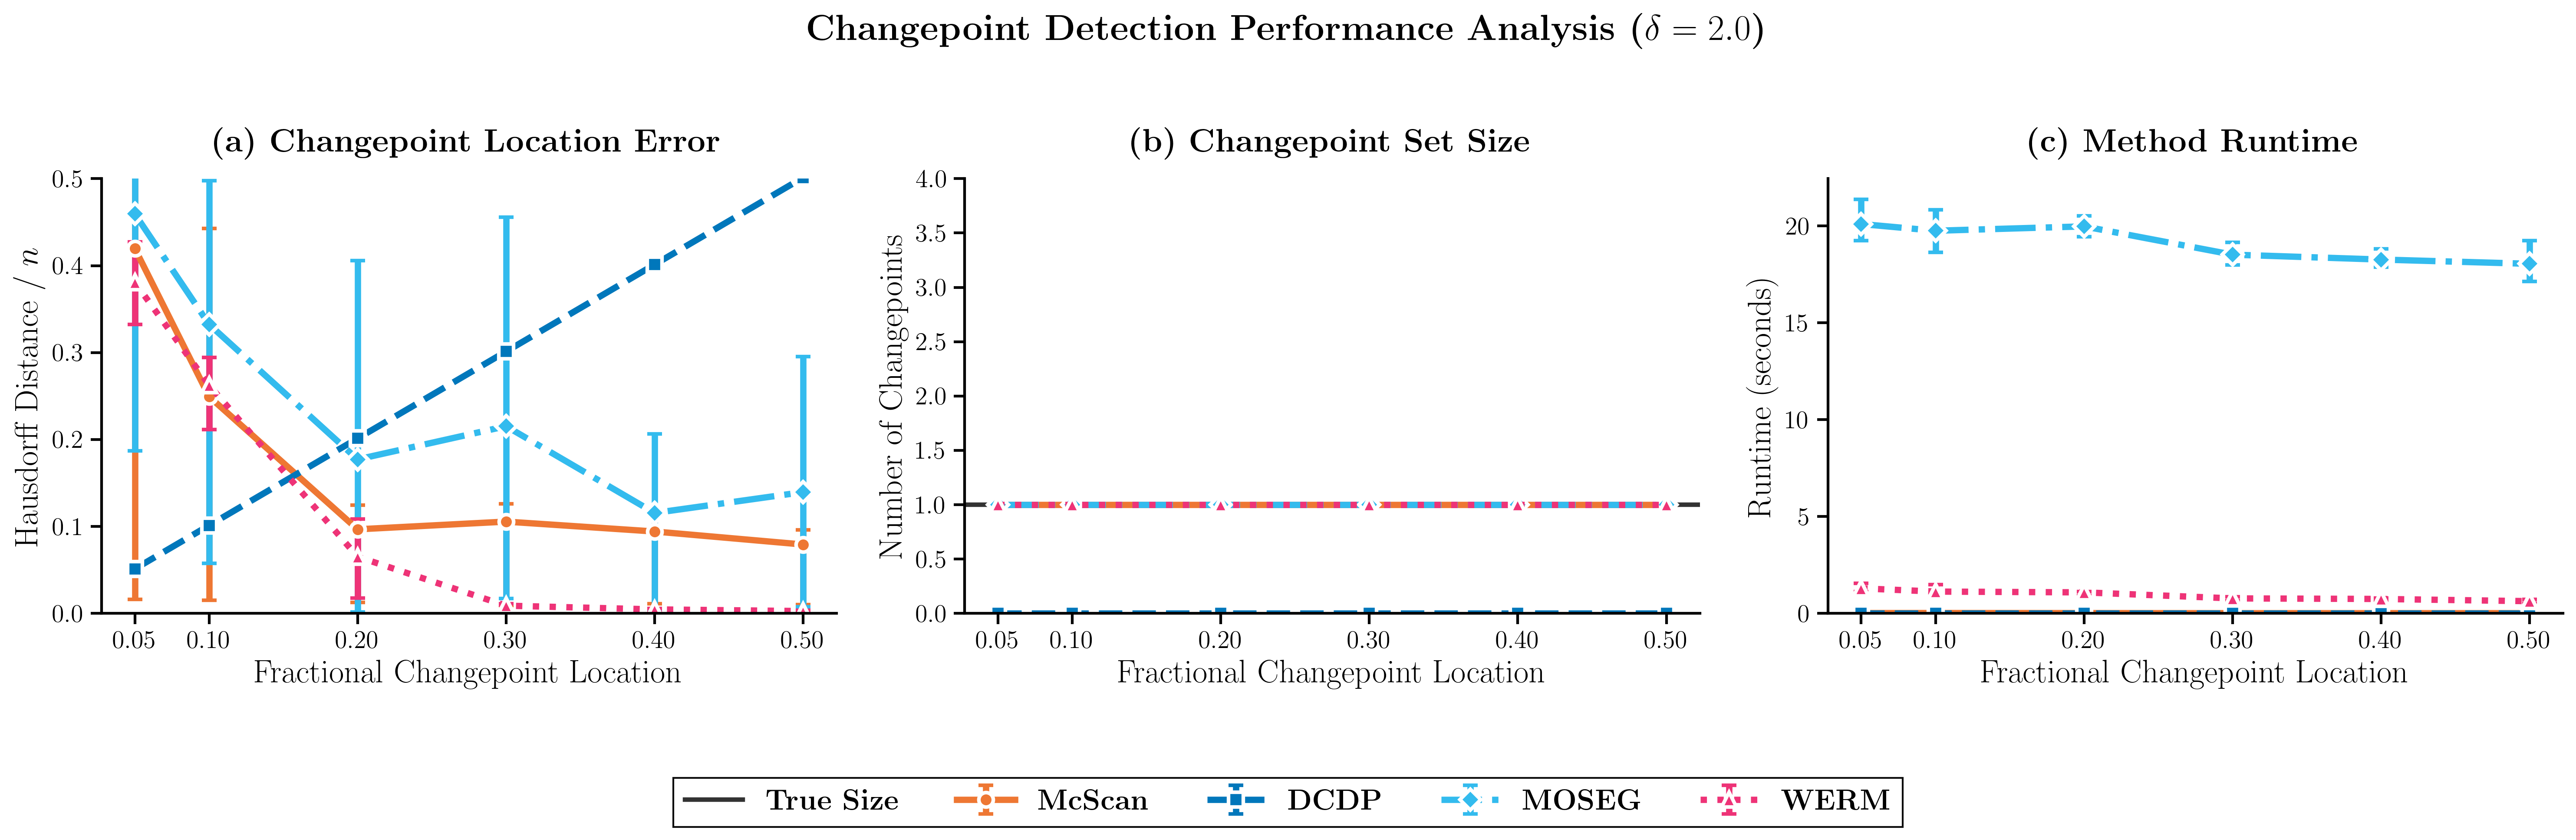

2. Confidence bands (publication style)...


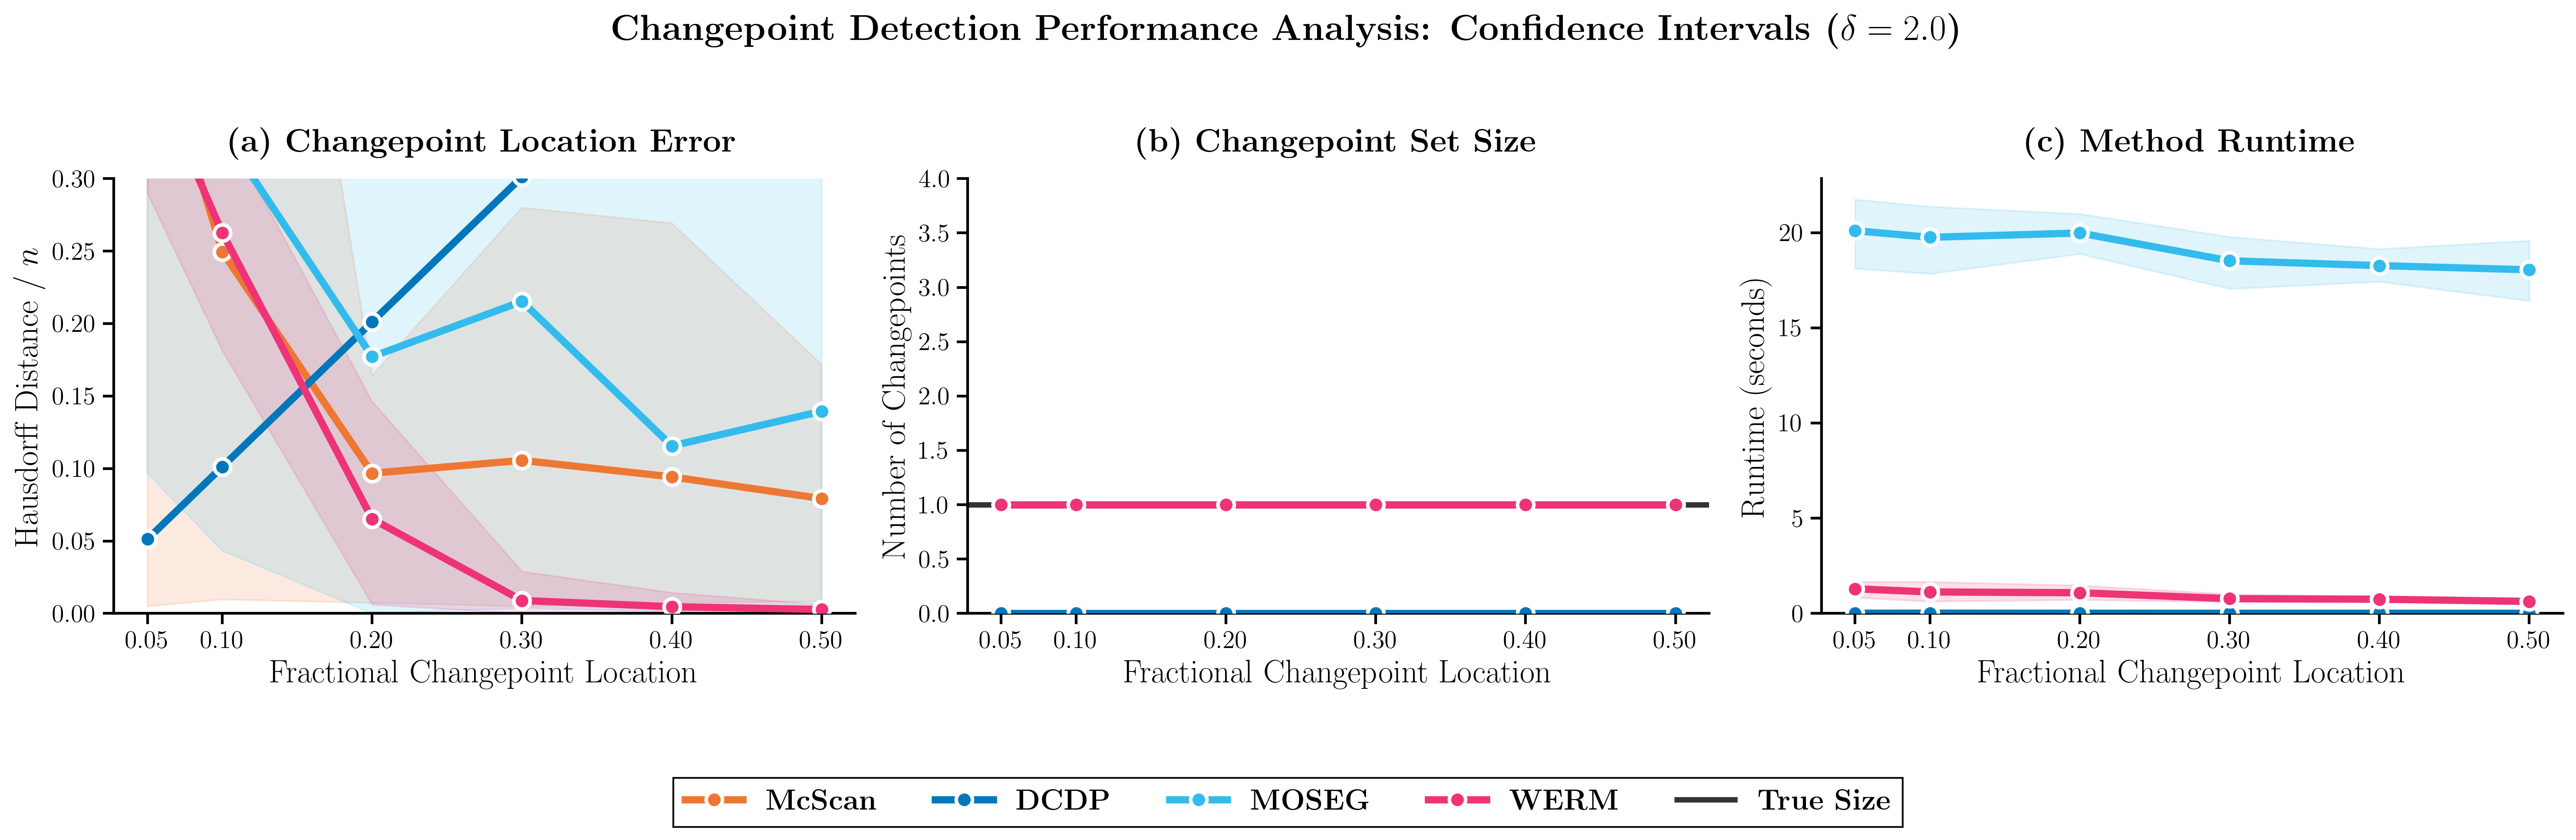

3. Box plots (publication style)...


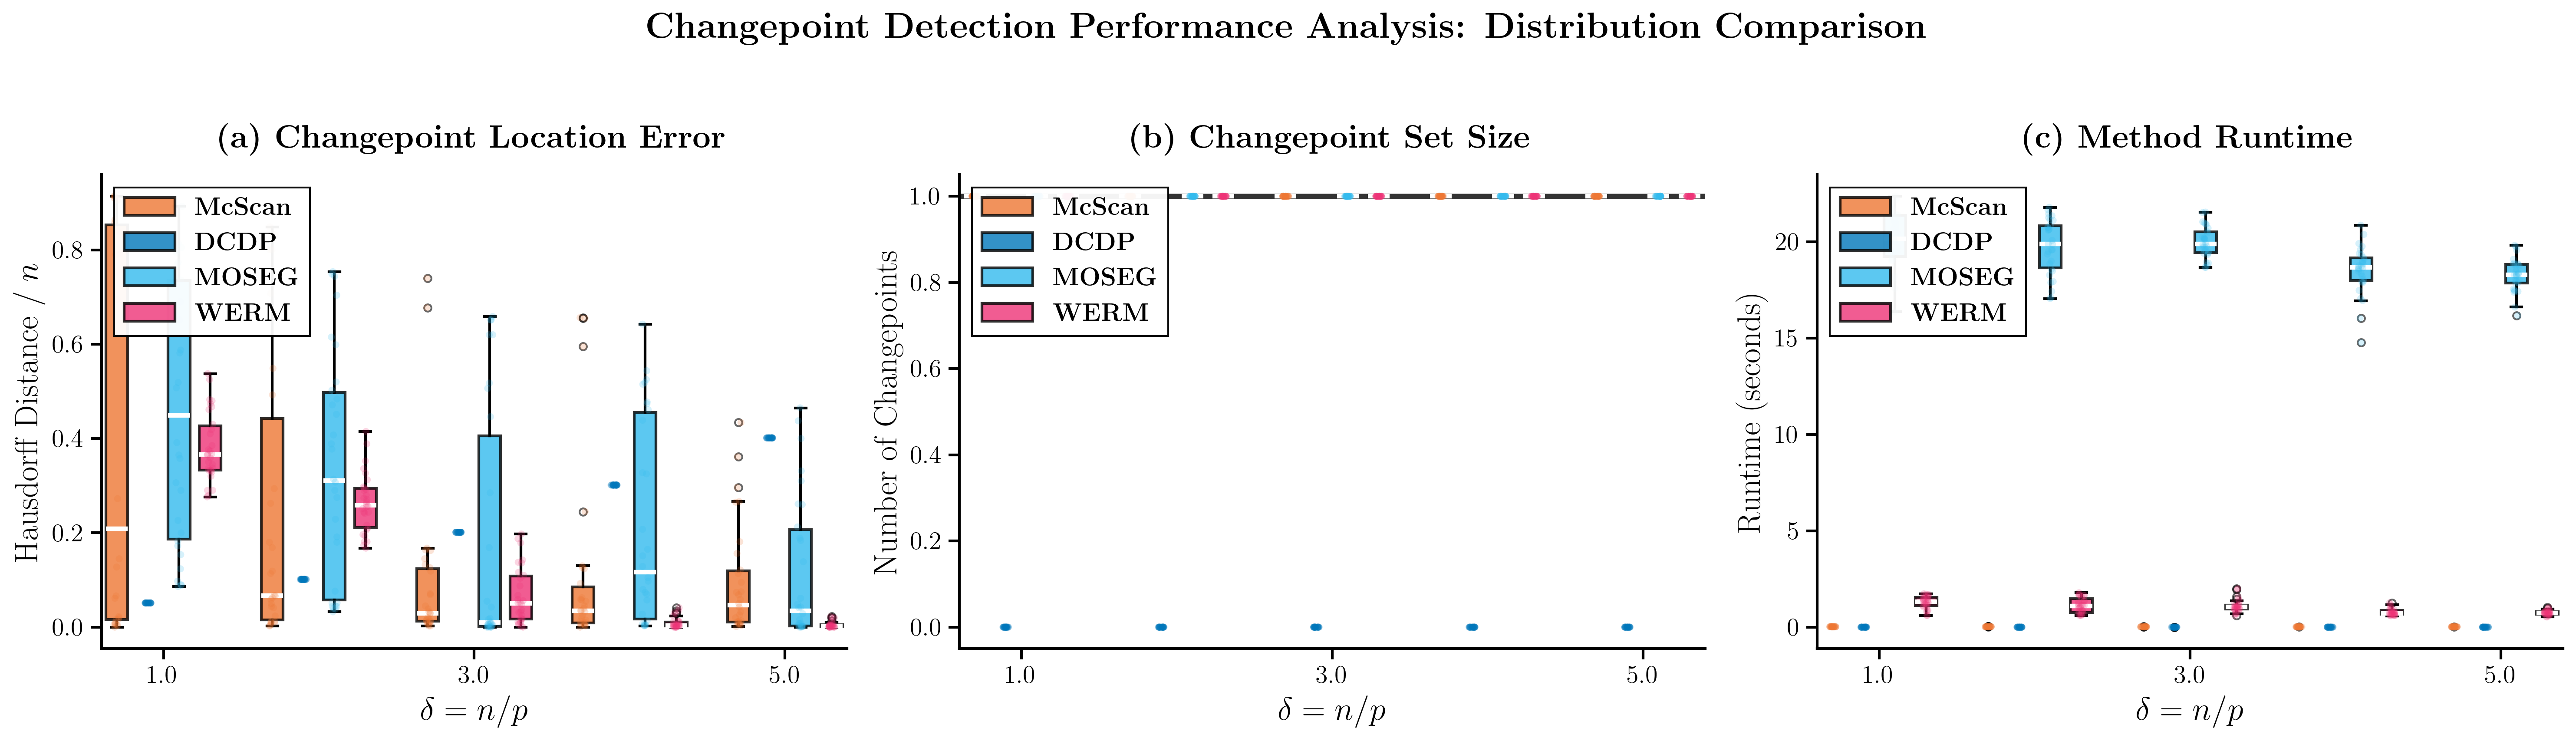

4. Enhanced changepoint histograms (publication style)...


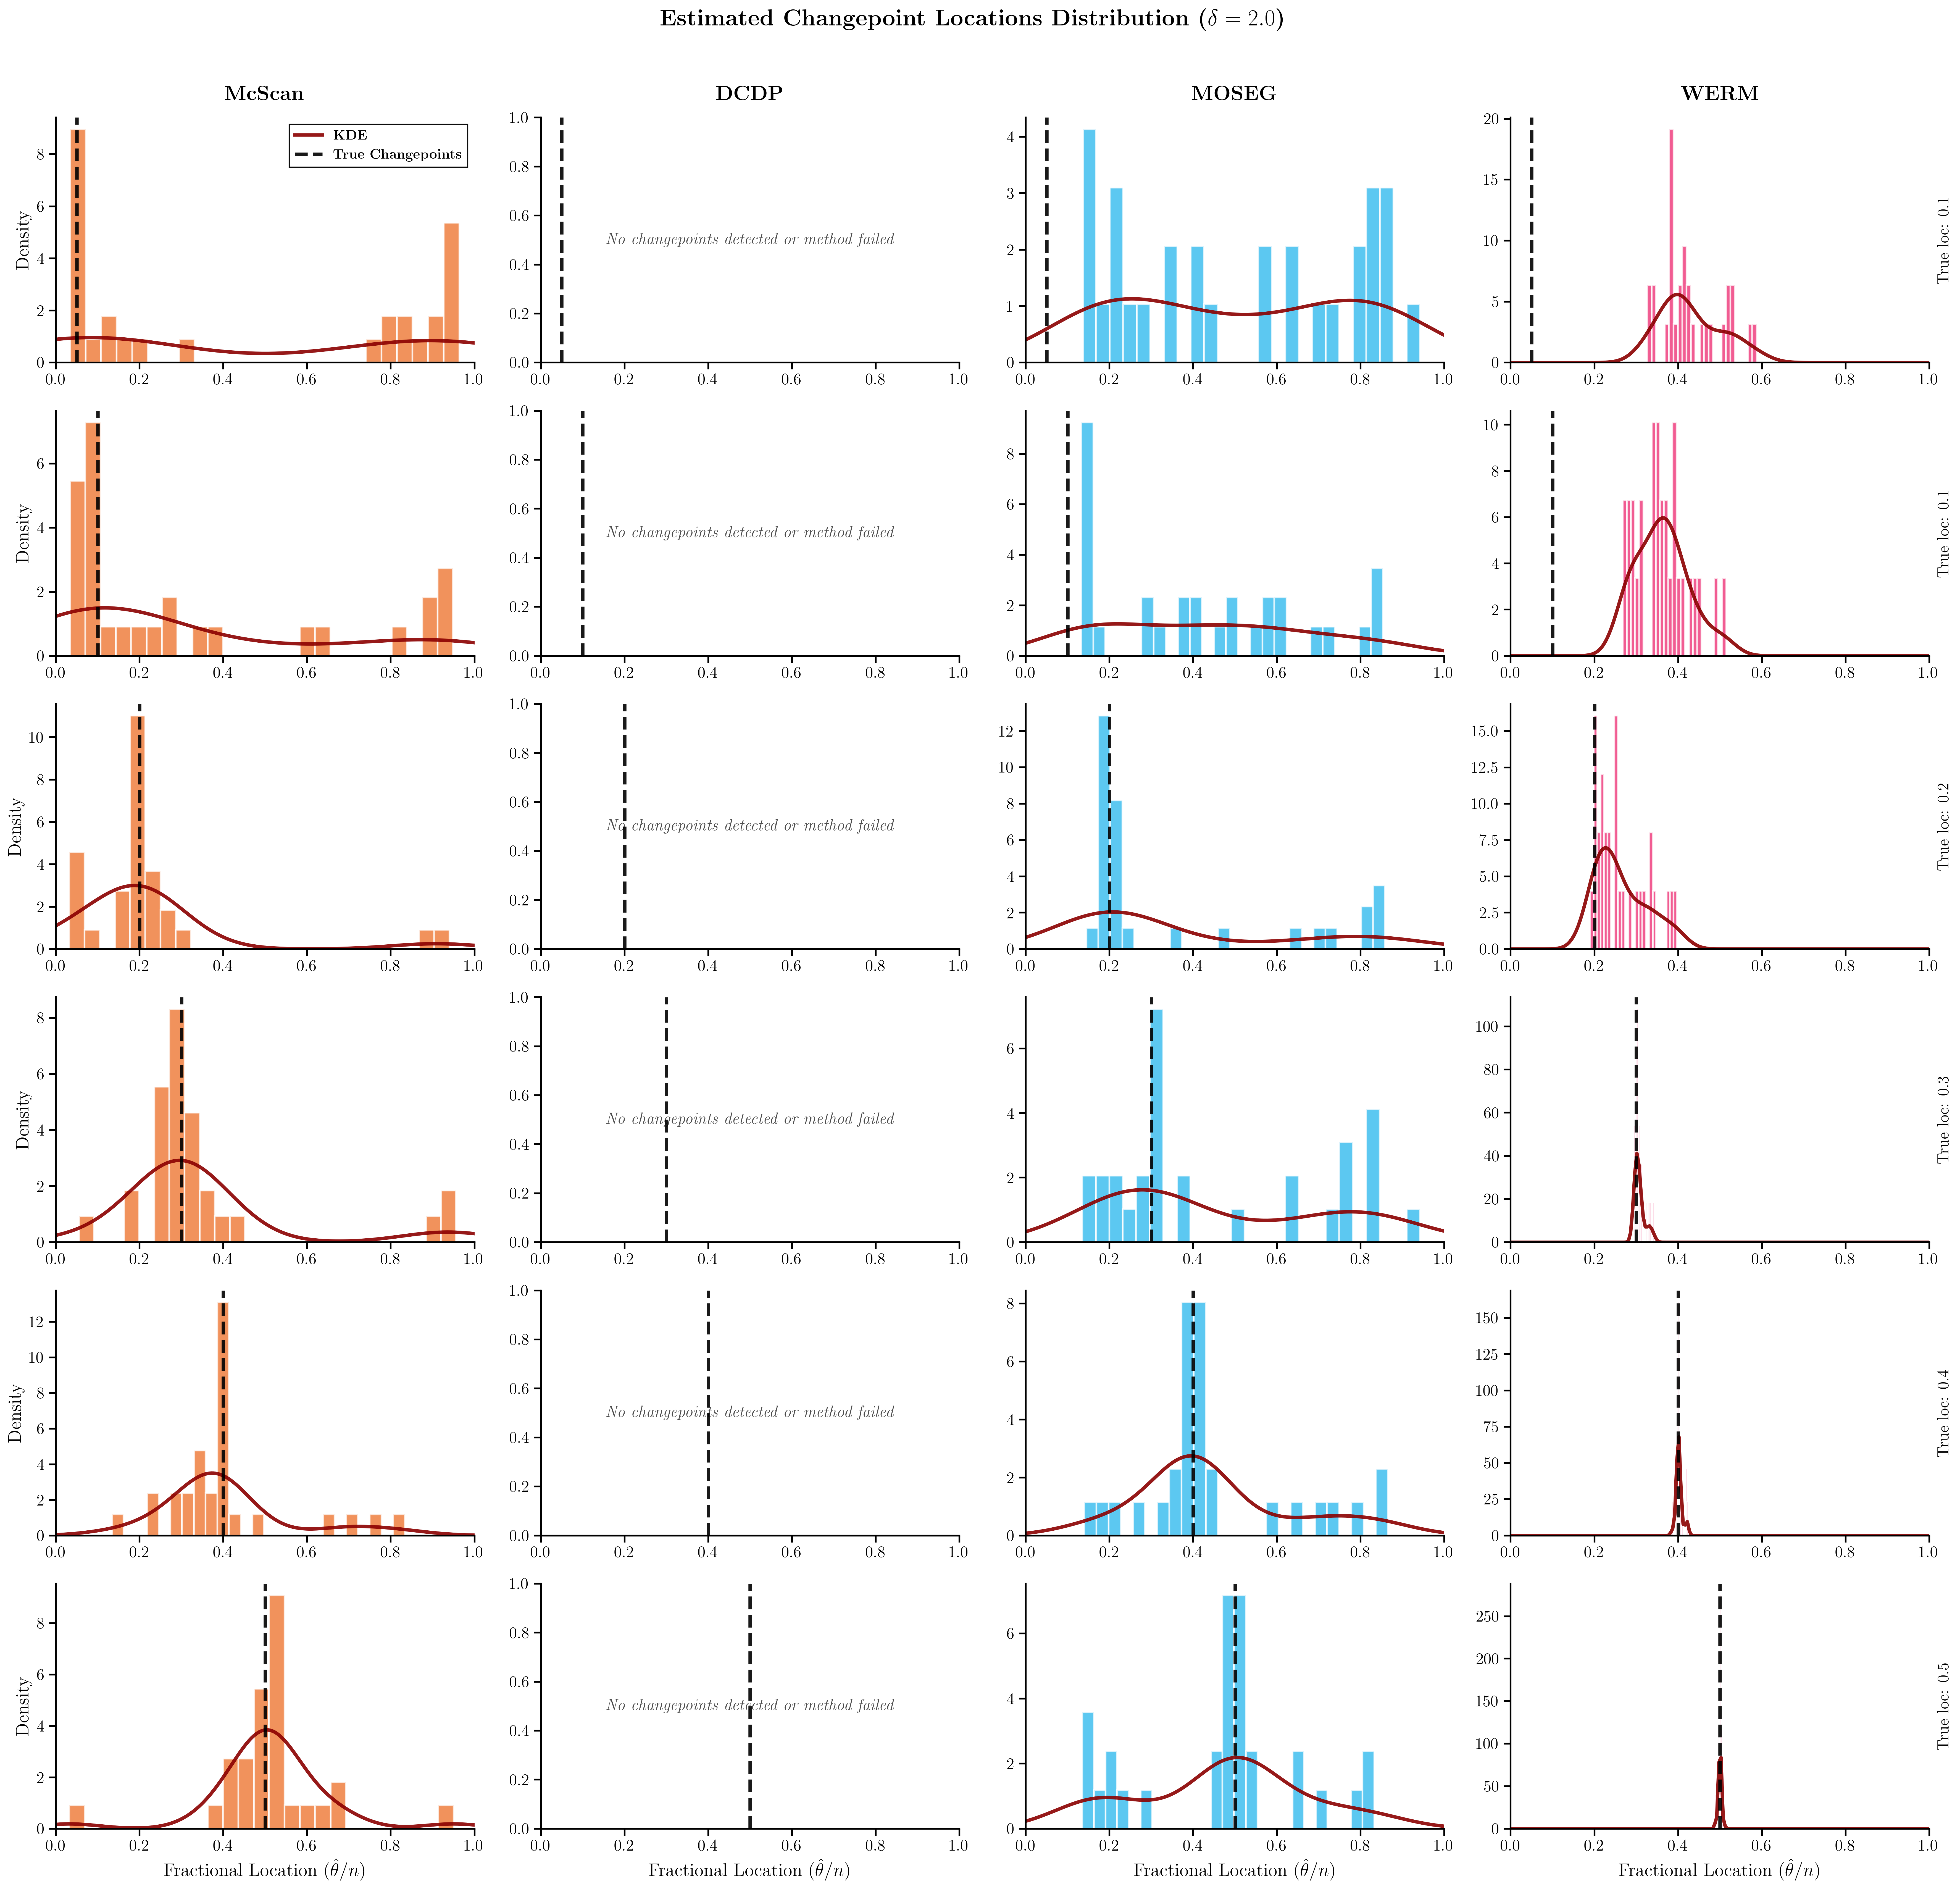

16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds
16:27:11 - Publication-ready plotting completed in 4.64 seconds


Search complete. Optimal GoF score: 225.2813
Search complete. Optimal GoF score: 242.4785
Search complete. Optimal GoF score: 204.5596
Search complete. Optimal GoF score: 218.6274
Search complete. Optimal GoF score: 202.8326
Search complete. Optimal GoF score: 214.9120
Search complete. Optimal GoF score: 211.5409
Search complete. Optimal GoF score: 204.2026
Search complete. Optimal GoF score: 207.2604
Search complete. Optimal GoF score: 209.7625
Search complete. Optimal GoF score: 217.7596
Search complete. Optimal GoF score: 237.5568
Search complete. Optimal GoF score: 214.1463
Search complete. Optimal GoF score: 217.3415
Search complete. Optimal GoF score: 219.0482
Search complete. Optimal GoF score: 237.4400
Search complete. Optimal GoF score: 210.5339
Search complete. Optimal GoF score: 209.2683
Search complete. Optimal GoF score: 200.1577
Search complete. Optimal GoF score: 227.3821
Search complete. Optimal GoF score: 211.5597
Search complete. Optimal GoF score: 203.7007
Search com

In [ ]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys

# Set a random seed for reproducibility
nprandom.seed(42)

# -----------------------------------------------------------------------------
# LOGGING SETUP
# -----------------------------------------------------------------------------

def setup_logging():
    """Setup comprehensive logging for the simulation"""
    # Create formatters
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )

    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create main logger
    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    # Console handler for main progress
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    # File handler for detailed logs
    file_handler = logging.FileHandler('logs/M1b_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    # Progress logger (separate to avoid cluttering main log)
    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    # Progress file handler
    progress_handler = logging.FileHandler('logs/M1b_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""

    def __init__(self, total_tasks, varying_param_list, num_trials, logger, param_name=""):
        self.total_tasks = total_tasks
        self.varying_param_list = varying_param_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.param_progress = {i: 0 for i in range(len(varying_param_list))}
        self.param_name = param_name

    def update(self, param_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        self.param_progress[param_idx] += 1

        # Calculate progress metrics
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            # Log progress
            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

            # Log parameter-specific progress
            if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
                param_status = []
                for i, param_val in enumerate(self.varying_param_list):
                    progress = self.param_progress[i]
                    # Ensure proper string representation for list/array-like params
                    val_str = f"[{param_val:.1f}]" if isinstance(param_val, (float, np.float64)) else f"{param_val}"
                    param_status.append(f"{self.param_name}={val_str}: {progress}/{self.num_trials}")

                self.logger.info(f"{self.param_name} progress: " + " | ".join(param_status))

# Global progress tracker (initialized later)
progress_tracker = True

# -----------------------------------------------------------------------------
# 1. Helper Function for a Single Parallel Job
# -----------------------------------------------------------------------------

def run_single_trial(params, p, L, noise_std, fixed_delta, M, gamma_candidates):
    """
    Executes a single simulation trial for a given fractional changepoint location.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker

    # Unpack parameters for this specific job
    i, fractional_chgpt_location, j = params

    trial_start_time = time.time()

    # Log trial start
    progress_logger.info(f"Starting trial {j+1}/{num_trials} for fractional_chgpt_location={fractional_chgpt_location} (index={i})")

    # --- Setup based on fixed_delta and fractional_chgpt_location ---
    δ = fixed_delta
    n = int(δ * p)
    # Ensure fractional_chgpt_location is an array for consistency
    true_chgpt_locations_arr = np.array([fractional_chgpt_location]) # Always assume single changepoint for this experiment
    true_chgpt_locations_fn = lambda n_len: (n_len * true_chgpt_locations_arr).astype(int)

    # Sparse Signal Prior Setup
    κ = 1.0
    α = 0.5 # fraction of nonzeros
    σ_l_arr = κ * np.sqrt(δ) * np.array([1, 1]) # signal standard deviation, multiply by sqrt(δ) to keep SNR constant as δ varies
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = nprandom.normal(0, 1, size=(n,)) * noise_std
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise

    # Generate a non-trivial p times p covariance matrix, like involving some s^r structure
    r = 0.2  # Correlation coefficient for off-diagonal elements
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))
    # Right multiply X by the square root of Sigma to introduce correlation
    X = X @ np.linalg.cholesky(Sigma).T

    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    # Important: for competing methods, we usually require something like X_ij ~ N(0, 1) (not 1/n),
    # so we rescale X and B̃ accordingly to keep Θ the same.
    X_scaled = X * np.sqrt(n) # Use this for methods expecting N(0,1) features
    B̃_scaled = B̃ / np.sqrt(n)

    Θ = X_scaled @ B̃_scaled # Keep Θ consistent based on scaled X and B̃
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)

    # Standardize y
    y_standardized = np.asarray(y / (α*κ**2 + noise_std**2))
    # print(f"y std: {np.std(y_standardized):.4f}, mean: {np.mean(y_standardized):.4f}")

    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators ---
    trial_results = {}
    methods_status = {} # To track success/failure of each method in this trial

    # Method 1: McScan Weighted ERM
    method_name = 'McScan'
    try:
        method_start = time.time()
        # print(f"Running {method_name} on params: ", params)
        cp_mcscan = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized, num_chgpts = len(true_chgpt_locations_arr)))
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_mcscan, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_mcscan[cp_mcscan != -1])
        trial_results[f'chgpts_{method_name}'] = cp_mcscan.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for fractional_chgpt_location={fractional_chgpt_location}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([]) # Store empty array for failed changepoints
        methods_status[method_name] = False

    # Method 2: DCDP (Dynamic Changepoint Detection via Penalized Likelihood)
    method_name = 'DCDP'
    try:
        # print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        # cp_dcdp = np.asarray(WERM.comparison.DCDP(np.array(X_scaled), y_standardized, λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # Placeholder, because DCDP often outputs >10 change points, which is not relevant for this experiment setup.
        # If you need DCDP to run, uncomment the line above and ensure it's configured for single changepoint scenarios.
        cp_dcdp = np.array([-1])
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        # For DCDP, if it returns multiple CPs, we'll just evaluate against the closest one
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.closest_point_distance(cp_dcdp, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_dcdp[cp_dcdp != -1])
        trial_results[f'chgpts_{method_name}'] = cp_dcdp.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for fractional_chgpt_location={fractional_chgpt_location}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Method 3: MOSEG (Moving Segmentations)
    method_name = 'MOSEG'
    try:
        # print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        res = WERM.comparison.MOSEG(np.array(X_scaled), y_standardized, num_chgpts=len(true_chgpt_locations_arr))
        cp_moseg = res[2]  # Returns the refined estimate
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_moseg, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_moseg[cp_moseg != -1])
        trial_results[f'chgpts_{method_name}'] = cp_moseg.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for fractional_chgpt_location={fractional_chgpt_location}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Method 4: WERM (Weighted ERM)
    method_name = 'WERM'
    try:
        print(f"Running {method_name} on params: ", params)
        method_start = time.time()
        # Delta = lambda n: int(n/40)
        Delta = lambda n: 1
        gamma_hat_1 = 0.0
        cp_werm = WERM.estimators.weighted_erm(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_1,
            L_is_upper_bound=False, return_B_hat=False,
            brute_force=True, P_func=P_func)
        method_time = time.time() - method_start
        trial_results[f'runtime_{method_name}'] = method_time
        trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp_werm, true_chgpts)
        trial_results[f'size_{method_name}'] = len(cp_werm[cp_werm != -1])
        trial_results[f'chgpts_{method_name}'] = cp_werm.copy()
        methods_status[method_name] = True
    except Exception as e:
        main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
        trial_results[f'runtime_{method_name}'] = np.nan
        trial_results[f'haus_{method_name}'] = np.nan
        trial_results[f'size_{method_name}'] = np.nan
        trial_results[f'chgpts_{method_name}'] = np.array([])
        methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = true_chgpt_locations_arr.copy()
    trial_results['methods_status'] = methods_status # Store status for this trial

    trial_total_time = time.time() - trial_start_time

    # Log detailed trial completion
    progress_logger.info(
        f"Completed trial {j+1} for fractional_chgpt_location={fractional_chgpt_location}: "
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s, "
        f"McScan={'OK' if methods_status['McScan'] else 'FAIL'} ({trial_results['runtime_McScan']:.1f}s), "
        f"DCDP={'OK' if methods_status['DCDP'] else 'FAIL'} ({trial_results['runtime_DCDP']:.1f}s), "
        f"MOSEG={'OK' if methods_status['MOSEG'] else 'FAIL'} ({trial_results['runtime_MOSEG']:.1f}s), "
        f"WERM={'OK' if methods_status['WERM'] else 'FAIL'} ({trial_results['runtime_WERM']:.1f}s))"
    )

    # Update global progress tracker
    if progress_tracker:
        progress_tracker.update(i)

    # Return the indices and the dictionary of results for this trial
    return i, j, trial_results

# -----------------------------------------------------------------------------
# 2. Main Script Setup
# -----------------------------------------------------------------------------

main_logger.info("Starting McScan, DCDP, MOSEG, WERM simulation M1b with enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 2 # L=2 signals, implying L-1 = 1 changepoint
noise_std = np.sqrt(0.25)
fixed_delta = 4.0  # Fixed delta value
fractional_chgpt_locations_list = np.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5]) # Varying changepoint locations (each representing one true changepoint)
num_trials = 30
n_jobs = -1 # Use all available CPU cores

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f"  p (features): {p}")
main_logger.info(f"  L (signals): {L} (implying {L-1} changepoint(s))")
main_logger.info(f"  noise_std: {noise_std}")
main_logger.info(f"  Fixed delta: {fixed_delta}")
main_logger.info(f"  Varying fractional_chgpt_locations: {fractional_chgpt_locations_list}")
main_logger.info(f"  num_trials: {num_trials}")
main_logger.info(f"  n_jobs: {n_jobs}")
main_logger.info(f"  Total tasks: {len(fractional_chgpt_locations_list) * num_trials}")

# Methods to be evaluated
methods_to_evaluate = ['McScan', 'DCDP', 'MOSEG', 'WERM']

# Results Storage
results = {
    # Store successful trial counts per method and changepoint location
    'successful_trials': {method: np.zeros(len(fractional_chgpt_locations_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'fractional_chgpt_locations_values': [] # Store the actual fractional location for plotting
}

# Dynamically add result arrays for each method and metric
for method in methods_to_evaluate:
    results[f'haus_{method}'] = np.full((len(fractional_chgpt_locations_list), num_trials), np.nan) # Initialize with NaN
    results[f'size_{method}'] = np.full((len(fractional_chgpt_locations_list), num_trials), np.nan)
    results[f'runtime_{method}'] = np.full((len(fractional_chgpt_locations_list), num_trials), np.nan)
    results[f'chgpts_{method}'] = [] # Storing all changepoints for histograms

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)

# L1 Penalty function
reg_constant = 1e-3
def P_func(beta):
    """L1 penalty function for regularization"""
    return reg_constant * jnp.sum(jnp.abs(beta))

# Gamma candidates for cross-validation of WERM (if needed)
gamma_candidates = np.logspace(-1, 2, 5)

# -----------------------------------------------------------------------------
# 3. Parallel Execution
# -----------------------------------------------------------------------------

# Create a list of all tasks to be executed
tasks = [(i, loc, j) for i, loc in enumerate(fractional_chgpt_locations_list) for j in range(num_trials)]

main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Expected computation time estimation
single_trial_estimate = 30.0 * len(methods_to_evaluate) # Rough estimate in seconds per trial (adjusted for all methods)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)

main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

# Initialize progress tracker
progress_tracker = ProgressTracker(len(tasks), fractional_chgpt_locations_list, num_trials, main_logger, param_name="fractional_chgpt_location")

simulation_start_time = time.time()

# Run all trials in parallel
try:
    # Run parallel computation
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L, # Pass L to the trial function
            noise_std=noise_std,
            fixed_delta=fixed_delta,
            M=M,
            gamma_candidates=gamma_candidates
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )

    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time

    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)

except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# -----------------------------------------------------------------------------
# 4. Aggregate Results
# -----------------------------------------------------------------------------

main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

# Populate the results dictionary from the list returned by the parallel execution
for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    chgpt_loc_idx = i # Renaming for clarity as we are now varying changepoint location
    for method in methods_to_evaluate:
        # Only store results if the method succeeded in this trial
        if trial_result['methods_status'][method]:
            results[f'haus_{method}'][chgpt_loc_idx, j] = trial_result[f'haus_{method}']
            results[f'size_{method}'][chgpt_loc_idx, j] = trial_result[f'size_{method}']
            results[f'runtime_{method}'][chgpt_loc_idx, j] = trial_result[f'runtime_{method}']
            results['successful_trials'][method][chgpt_loc_idx] += 1
        results[f'chgpts_{method}'].append((chgpt_loc_idx, trial_result[f'chgpts_{method}']))


    # Store changepoint locations and metadata for histogram plotting
    results['true_chgpts'].append((chgpt_loc_idx, trial_result['true_chgpts']))
    results['n_values'].append((chgpt_loc_idx, trial_result['n']))
    results['fractional_chgpt_locations_values'].append((chgpt_loc_idx, fractional_chgpt_locations_list[chgpt_loc_idx]))


aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)

for i, chgpt_loc in enumerate(fractional_chgpt_locations_list):
    main_logger.info(f"Fractional Changepoint Location = {chgpt_loc:.1f}:")
    for method in methods_to_evaluate:
        # Use nanmean and nanstd to ignore NaN values (failed trials)
        avg_haus = np.nanmean(results[f'haus_{method}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method}'][i, :])
        avg_size = np.nanmean(results[f'size_{method}'][i, :])
        std_size = np.nanstd(results[f'size_{method}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method}'][i, :])
        num_success = results['successful_trials'][method][i]

        main_logger.info(f"  {method} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f"  {method} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f"  {method} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f"  {method} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'font.size': 14,          # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,      # Larger axis labels
    'axes.titlesize': 18,      # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 300,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT

print(f"Using palette: {PAL[:len(methods_to_evaluate)]} (Paul Tol Vibrant)")

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis ($\delta = 2.0$)}', fontsize=20, y=0.98)

    # Calculate percentiles for asymmetric error bars
    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1) # Use nanmean
        p25 = np.nanpercentile(data, 25, axis=1) # Use nanpercentile
        p75 = np.nanpercentile(data, 75, axis=1) # Use nanpercentile

        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)

        return [lower_errors, upper_errors]

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    markers = ['o', 's', 'D', '^']
    linestyles = ['-', '--', '-.', ':']
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method in enumerate(methods):
        data = results[f'haus_{method}']
        # Filter out rows where all values are NaN before calculating means and errors for plotting
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices): # If all trials failed for this method/chgpt_loc, skip plotting
            main_logger.warning(f"No successful trials for {method} (Hausdorff). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(fractional_chgpt_locations_list, means, yerr=errors,
                    label=labels[i], marker=markers[i], ls=linestyles[i],
                    color=colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'Fractional Changepoint Location', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)

    # Cleaner x-axis with fewer ticks
    ax.set_xticks(fractional_chgpt_locations_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method in enumerate(methods):
        data = results[f'size_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Size). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(fractional_chgpt_locations_list, means, yerr=errors,
                    label=labels[i], marker=markers[i], ls=linestyles[i],
                    color=colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    # Corrected: The true number of changepoints is L-1, which is 1 for L=2
    ax.axhline(y=1, color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2)) # L is 2, so this will be (0, 4)
    ax.set_xlabel(r'Fractional Changepoint Location', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)

    ax.set_xticks(fractional_chgpt_locations_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method in enumerate(methods):
        data = results[f'runtime_{method}']
        valid_indices = ~np.all(np.isnan(data), axis=1)
        if not np.any(valid_indices):
            main_logger.warning(f"No successful trials for {method} (Runtime). Skipping plot for this metric.")
            continue

        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)

        ax.errorbar(fractional_chgpt_locations_list, means, yerr=errors,
                    label=labels[i], marker=markers[i], ls=linestyles[i],
                    color=colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'Fractional Changepoint Location', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)

    ax.set_xticks(fractional_chgpt_locations_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals ($\delta = 2.0$)}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]

        for method_idx, method in enumerate(methods):
            data = results[f'{metric}_{method}']
            valid_indices = ~np.all(np.isnan(data), axis=1)
            if not np.any(valid_indices):
                main_logger.warning(f"No successful trials for {method} ({metric}). Skipping plot for this metric.")
                continue

            means = np.nanmean(data, axis=1)

            # Calculate confidence intervals (10th and 90th percentiles), ignoring NaNs
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)

            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            # Plot confidence band first (so it's behind the line)
            ax.fill_between(fractional_chgpt_locations_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)

            # Plot mean line with markers
            ax.plot(fractional_chgpt_locations_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        # Add true size line for size plot
        if metric == 'size':
            # Corrected: The true number of changepoints is 1 (L-1) for each signal
            ax.axhline(y=1, color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)

        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'Fractional Changepoint Location', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Cleaner axes
        ax.set_xticks(fractional_chgpt_locations_list)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    # Updated methods and labels for plotting
    methods = methods_to_evaluate
    colors = [PAL[0], PAL[1], PAL[2], PAL[3]]
    labels = [r'\textbf{McScan}', r'\textbf{DCDP}', r'\textbf{MOSEG}', r'\textbf{WERM}']


    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]

        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []

            # Adjust spacing between boxes for each delta
            spacing = len(methods) + 1 # Add extra space between groups
            for method_idx, method in enumerate(methods):
                data = results[f'{metric}_{method}'][delta_idx, :]
                # Filter out NaN values for box plot to only show successful trials
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0: # Only plot if there is valid data
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")


            # Create publication-ready box plots
            # if len(box_data) > 0:
            #     bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
            #                    patch_artist=True, showfliers=True,
            #                    flierprops=dict(marker='o', markersize=4, alpha=0.6),
            #                    medianprops=dict(color='white', linewidth=2.5),
            #                    boxprops=dict(linewidth=1.5),
            #                    whiskerprops=dict(linewidth=1.5),
            #                    capprops=dict(linewidth=1.5))

            #     # Color the boxes
            #     for patch, color in zip(bp['boxes'], box_colors):
            #         patch.set_facecolor(color)
            #         patch.set_alpha(0.8)
            #         patch.set_edgecolor('black')
                    
            if len(box_data) > 0:
                # Create box plot
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))

                # Color the boxes
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

                # Overlay faint scatter points for each box
                for i, (points, x_pos, color) in enumerate(zip(box_data, box_positions, box_colors)):
                    # Add random jitter for horizontal spread
                    jitter = 0.1
                    x_jittered = x_pos + np.random.uniform(-jitter, jitter, size=len(points))
                    ax.scatter(x_jittered, points, alpha=0.2, color=color, s=15, edgecolor='none', zorder=3)

        # Set x-axis labels - only show every other delta for cleanliness
        delta_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        # Add legend
        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                       alpha=0.8, edgecolor='black',
                                       linewidth=1.5, label=labels[i])
                         for i in range(len(methods))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                 frameon=True, edgecolor='black', framealpha=0.95)

        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                      linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, fractional_chgpt_locations_list, methods_to_plot, p_val, fixed_delta_val):
    """
    Publication-ready changepoint location histograms
    """

    method_names = {
        'McScan': r'\textbf{McScan}',
        'DCDP': r'\textbf{DCDP}',
        'MOSEG': r'\textbf{MOSEG}',
        'WERM': r'\textbf{WERM}'
    }

    # Use consistent colors from main palette
    method_colors = {
        'McScan': PAL[0],
        'DCDP': PAL[1],
        'MOSEG': PAL[2],
        'WERM': PAL[3]
    }

    selected_chgpt_loc_indices = list(range(len(fractional_chgpt_locations_list)))
    selected_chgpt_locations = fractional_chgpt_locations_list

    fig, axes = plt.subplots(len(selected_chgpt_locations), len(methods_to_plot),
                             figsize=(6*len(methods_to_plot), 4*len(selected_chgpt_locations)))

    # Handle subplot configurations
    if len(selected_chgpt_locations) == 1 and len(methods_to_plot) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_chgpt_locations) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution ($\delta = 2.0$)}',
                 fontsize=20, y=0.98)

    for row, (chgpt_loc_idx, chgpt_loc) in enumerate(zip(selected_chgpt_loc_indices, selected_chgpt_locations)):
        n = int(fixed_delta_val * p_val) # Use fixed_delta_val and p_val to calculate n

        for col, method in enumerate(methods_to_plot):
            ax = axes[row, col]
            ax.set_facecolor('white')

            # Collect changepoints for the current changepoint location and method
            all_chgpts = []
            # Iterate through the raw stored changepoint results to filter by chgpt_loc_idx
            for stored_chgpt_loc_idx, chgpts_data in results[f'chgpts_{method}']:
                if stored_chgpt_loc_idx == chgpt_loc_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1] # Filter out -1 sentinels
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors[method],
                                                density=True, edgecolor='white',
                                                linewidth=1.5)

                # Add KDE overlay if we have enough points
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde # Moved this import inside function
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')

            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            # True changepoints with thicker lines
            current_true_chgpts = None
            for stored_chgpt_loc_idx, true_chgpts_data in results['true_chgpts']:
                if stored_chgpt_loc_idx == chgpt_loc_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n # Ensure true changepoints are also fractional
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")

            ax.set_xlim(0, 1)

            # Only label bottom row and leftmost column
            if row == len(selected_chgpt_locations)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names[method]}', fontsize=18, pad=15)

            # Add fractional changepoint location value annotation
            if col == len(methods_to_plot)-1:
                ax.text(1.02, 0.5, f'True loc: {chgpt_loc:.1f}', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                   edgecolor='black', framealpha=0.95)

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()

print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, fractional_chgpt_locations_list, methods_to_evaluate, p_val=p, fixed_delta_val=fixed_delta)

plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Optional: Save figures in high quality
# plt.savefig('weighted_erm_analysis.pdf', dpi=300, bbox_inches='tight')
# plt.savefig('weighted_erm_analysis.png', dpi=300, bbox_inches='tight')

# Save results to a file for later analysis, with all relevant experiment parameters included also in the name
import pickle
filename_suffix = f"p{p}_L{L}_noisestd{noise_std}_delta{fixed_delta}_chgptlocs{'_'.join(map(str, fractional_chgpt_locations_list))}_{num_trials}.pkl".replace('.', 'p') # replace '.' for filename
with open(f"results/M1b_all_methods_results_{filename_suffix}", 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'fixed_delta': fixed_delta,
            'num_trials': num_trials,
            'fractional_chgpt_locations_list': fractional_chgpt_locations_list,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'] # Save successful trial counts
        }
    }, f)